# 01 · 数据读取与分析

**任务**：根据比赛记录预测力量举选手的三项总成绩 `TotalKg`（kg），评估指标 RMSE（越低越好）。训练集 105,000 行、测试集 45,000 行；16 个特征，其中 3 个数值（年龄、体重、比赛年份）、13 个类别（性别、装备、年龄组、级别、是否药检、国籍、州、联盟、比赛地等）。

本 notebook 读取 `data/` 中的原始 CSV，核对数据，做探索分析和数据质量检查，并说明之后所有实验共用的**固定五折**。它只读数据、不训练，也不写结果文件；Colab 普通 CPU 运行时即可。

| notebook | 内容 |
|---|---|
| **01_data_exploration** | 读取与核对原始数据、探索分析、记录精度与「双胞胎」、数据质量检查、固定五折 |
| **02_feature_engineering** | 四轮特征（记录精度、跨地参赛、比赛背景、运动员历史与生涯、基于成绩的特征）及五折消融（实验 07、09、10、14） |
| **03_model_selection** | 早期基线、CatBoost 参数、其他模型与相对力量目标、堆叠方式、目标变量工程、模型大比较（实验 08、13） |
| **04_final_model** | 最终集成：8 个模型 × 5 折 × 3 种子 + 全量重训、NNLS 融合、双胞胎 + 同一运动员平滑、成对相似度平滑、提交文件（实验 11、12、15–17） |
| **05_error_analysis** | 最终残差、同一运动员与双胞胎结构、第二层做法比较、数据清洗实验、未采用的方法、交叉验证与公开榜 |

原始数据在 `data/`；结果保存在 `artifacts/` 下与 notebook 同名的目录。「实验 07–17」是实验的原始编号，代码注释和 RESULTS.md 沿用这些编号。

In [1]:
# 环境、路径与通用设置（5 本 notebook 相同）
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('找不到项目目录（应包含 data/train.csv 与 data/test.csv）；请设置环境变量 PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # 原始 CSV（只读）
ARTIFACTS = PROJECT_DIR / 'artifacts'           # 每本 notebook 的结果在与它同名的子目录
SEED = 42                                       # 固定五折：KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 外层训练部分内留 10% 早停
MAX_ROUNDS = 20000
MODELS = ['lgb', 'xgb', 'catboost']             # 特征消融用的三个模型（每折内的运行顺序：快的先跑）
RUN_ONLY = None                                 # 只跑部分变体时写成列表；None 表示全部
KEEP_DELTA = -0.05                              # kg：平均 ΔRMSE ≤ −0.05 且 ≥ 4/5 折更好才保留
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # 01 与 05 没有训练开关
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('一次只打开一个训练开关：不同实验的代码共用变量名。跑完一个、重启运行时后再打开下一个')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """只在训练时调用：安装固定版本的 CatBoost 与 pytabkit，导入训练用的库，确认 Colab 分配了 GPU。"""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('当前运行时已经导入另一版 CatBoost；请重启运行时后从头运行')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # 安装或导入失败时其余模型照常运行
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'需要 CatBoost {CATBOOST_VERSION}；实际为 {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('训练需要 GPU：请在 Colab「更改运行时类型」中选择 T4 GPU 后从头运行')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {'catboost': catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('版本         :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit 不可用，RealMLP / TabM 会在预检中跳过：', PYTABKIT_ERROR)


print(f'项目：{PROJECT_DIR}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('打开的训练开关：', [k for k, v in TRAIN.items() if v])

Mounted at /content/drive
项目：/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting
Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3


## 1. 读取并核对原始数据

核对 SHA-256（与所有实验时的数据逐字节一致）、形状、列分组和空值，并生成固定五折 `FOLD_IDS`。之后每本 notebook 都用同一个单元格读取数据。

In [2]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} 与原始数据不同；请检查数据文件')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # 不依赖 object / str dtype（pandas 2 与 3 都可用）
require(train.shape == (105000, 18) and test.shape == (45000, 17), '数据形状不符')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), '列分组不符')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), '出现空值')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}；每折验证行数：{np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17)；每折验证行数：[21000, 21000, 21000, 21000, 21000]


## 2. 字段概览

原始数据没有空值，缺失一律写成 `Unknown`（主要在州、比赛州、上级联盟）。

In [3]:
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
require(sample_submission.columns.tolist() == ['id', TARGET] and len(sample_submission) == len(test)
        and set(sample_submission['id']) == set(test['id']), '提交模板与测试集不一致')
both_raw = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)
overview = pd.DataFrame({
    '类型': ['数值' if c in RAW_NUM else '类别' for c in RAW_FEATURES],
    '取值个数（train+test）': [int(both_raw[c].nunique()) for c in RAW_FEATURES],
    '最常见取值': [str(both_raw[c].value_counts().index[0]) for c in RAW_FEATURES],
    '最常见取值占比': [float(both_raw[c].value_counts(normalize=True).iloc[0]) for c in RAW_FEATURES],
    'Unknown 占比': [float((both_raw[c].astype(str) == 'Unknown').mean()) for c in RAW_FEATURES],
}, index=RAW_FEATURES)
display(overview.round(3))
display(train[RAW_NUM + [TARGET]].describe().T.round(2))
print('提交模板：', sample_submission.shape, '，列', sample_submission.columns.tolist())

,类型,取值个数（train+test）,最常见取值,最常见取值占比,Unknown 占比
Age,数值,172,17.5,0.035,0.000
BodyweightKg,数值,8302,82.5,0.009,0.000
MeetYear,数值,62,2024,0.094,0.000
Sex,类别,3,M,0.691,0.000
Equipment,类别,5,Raw,0.621,0.000
AgeClass,类别,19,24-34,0.322,0.000
BirthYearClass,类别,8,24-39,0.392,0.030
WeightClassKg,类别,153,90,0.078,0.010
Tested,类别,2,Yes,0.762,0.000
Country,类别,152,USA,0.460,0.018


,count,mean,std,min,25%,50%,75%,max
Age,105000.0,28.54,12.06,0.5,19.50,25.0,34.0,92.50
BodyweightKg,105000.0,83.42,21.98,19.1,67.09,81.4,97.1,241.80
MeetYear,105000.0,2017.67,8.01,1966.0,2015.00,2019.0,2023.0,2026.00
TotalKg,105000.0,493.01,171.40,24.0,352.50,492.5,612.5,1363.05


提交模板： (45000, 2) ，列 ['id', 'TotalKg']


## 3. 目标变量 TotalKg

男女分布差别很大，体重与总成绩强相关但离散度很大：同样体重的选手，总成绩可以相差几百公斤。RMSE 约 76 kg 的误差，大部分来自特征里看不出的个人训练水平。

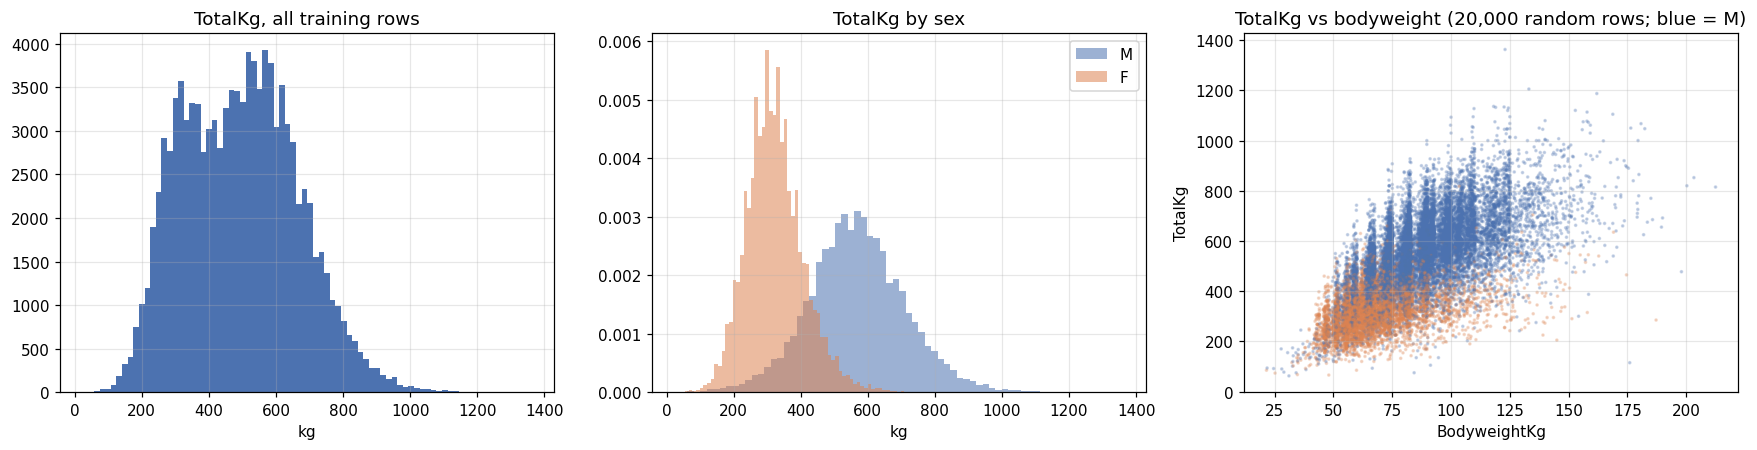

size   mean    std
Sex Equipment                      
F   Multi-ply     380  416.3  126.7
    Raw         21755  314.3   76.1
    Single-ply   6366  342.9  100.0
    Unlimited     521  333.2   85.0
    Wraps        3515  331.3   87.2
M   Multi-ply    2053  716.1  191.7
    Raw         43471  547.1  126.3
    Single-ply  17352  592.7  160.2
    Unlimited     545  569.3  162.3
    Wraps        9033  597.4  141.2
Mx  Raw             8  330.7   74.6
    Wraps           1  522.5    NaN

In [4]:
sex = train['Sex'].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(y, bins=80, color='#4c72b0')
axes[0].set_title('TotalKg, all training rows')
axes[0].set_xlabel('kg')
for value, colour in [('M', '#4c72b0'), ('F', '#dd8452')]:
    axes[1].hist(y[sex == value], bins=70, alpha=0.55, density=True, color=colour, label=value)
axes[1].legend()
axes[1].set_title('TotalKg by sex')
axes[1].set_xlabel('kg')
shown_rows = np.random.default_rng(SEED).choice(n_train, 20000, replace=False)
axes[2].scatter(train['BodyweightKg'].to_numpy()[shown_rows], y[shown_rows], s=2, alpha=0.25,
                c=np.where(sex[shown_rows] == 'M', '#4c72b0', '#dd8452'))
axes[2].set_xlabel('BodyweightKg')
axes[2].set_ylabel('TotalKg')
axes[2].set_title('TotalKg vs bodyweight (20,000 random rows; blue = M)')
plt.tight_layout()
plt.show()
display(train.groupby(['Sex', 'Equipment'])[TARGET].agg(['size', 'mean', 'std']).round(1))

## 4. 年龄、比赛年份与联盟

虚线是全部训练行的平均总成绩。

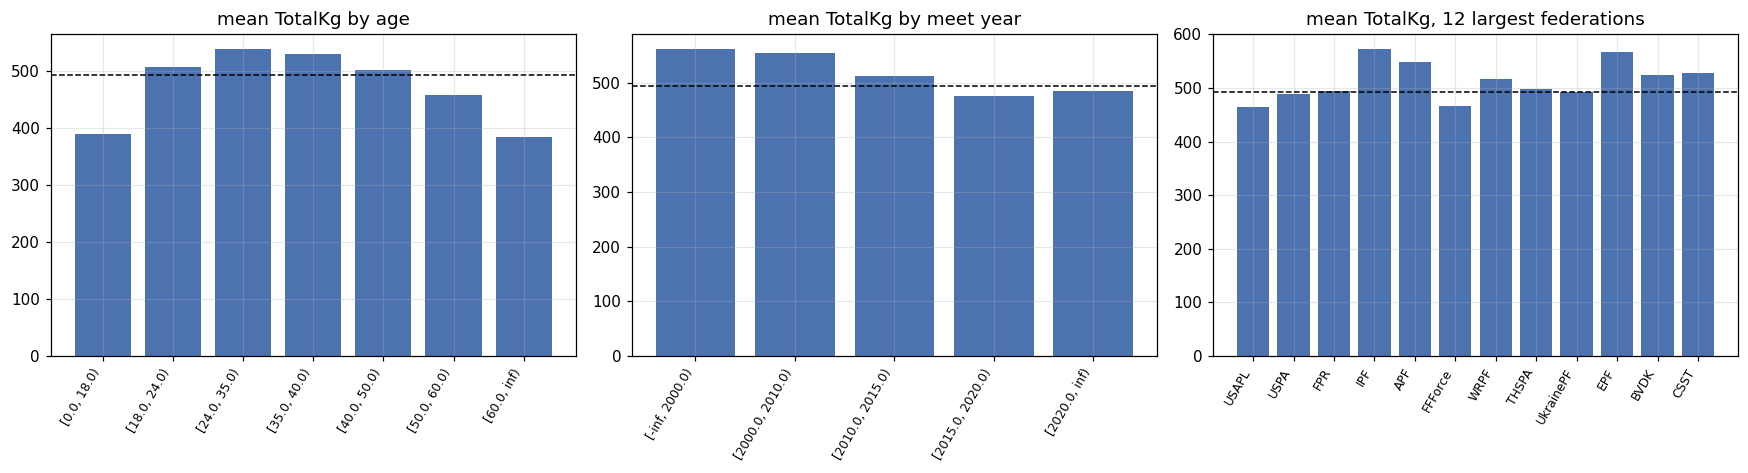

In [5]:
def mean_by(values, order=None):
    table = pd.DataFrame({'k': np.asarray(values).astype(str), 'y': y}).groupby('k')['y'].agg(['size', 'mean'])
    return table if order is None else table.reindex([o for o in order if o in table.index])


age_cut = pd.cut(train['Age'], [0, 18, 24, 35, 40, 50, 60, np.inf], right=False)
year_cut = pd.cut(train['MeetYear'], [-np.inf, 2000, 2010, 2015, 2020, np.inf], right=False)
largest_feds = train['Federation'].value_counts().head(12).index.tolist()
panels = [('mean TotalKg by age', mean_by(age_cut.astype(str), [str(c) for c in age_cut.cat.categories])),
          ('mean TotalKg by meet year', mean_by(year_cut.astype(str), [str(c) for c in year_cut.cat.categories])),
          ('mean TotalKg, 12 largest federations', mean_by(train['Federation'], largest_feds))]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (title, table) in zip(axes, panels):
    ax.bar(range(len(table)), table['mean'], color='#4c72b0')
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(table.index.tolist(), rotation=60, ha='right', fontsize=8)
    ax.axhline(y.mean(), color='black', ls='--', lw=1)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 5. 记录精度：数据里的隐藏信号

- **年龄 x.5**：只登记了出生年份时，年龄写成 x.5。不同联盟、不同级别的赛事登记习惯不同。
- **体重的小数位数**：整数、x.5、一位小数、两位小数，对应不同的称重和录入方式。

树模型按阈值切分数值，学不到「是不是 .5」「有几位小数」，所以 02 把它们做成显式特征（`P` 块）。在 v2 模型的残差里，USAPL 内整数年龄与 x.5 年龄的残差均值相差 24.5 kg，这是第一轮特征最强的证据。

In [6]:
def safe_mean(values):
    return float(np.mean(values)) if len(values) else np.nan


age_half = ((train['Age'] * 2).round() % 2).astype(int).to_numpy()      # 1 = 年龄是 x.5（只登记了出生年份）
bw = train['BodyweightKg']
is_int = np.isclose(bw, bw.round())
is_1dec = np.isclose(bw * 10, (bw * 10).round())
is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
bw_precision = np.select([is_int, is_half, is_1dec], ['整数', 'x.5', '其他一位小数'], default='两位小数')
precision_rows = []
for fed in ['（全部）'] + train['Federation'].value_counts().head(8).index.tolist():
    m = np.ones(n_train, dtype=bool) if fed == '（全部）' else (train['Federation'] == fed).to_numpy()
    precision_rows.append({'联盟': fed, '行数': int(m.sum()), 'x.5 年龄占比': age_half[m].mean(),
                           '平均总成绩：整数年龄': safe_mean(y[m & (age_half == 0)]),
                           '平均总成绩：x.5 年龄': safe_mean(y[m & (age_half == 1)]),
                           '两位小数体重占比': float((bw_precision[m] == '两位小数').mean())})
display(pd.DataFrame(precision_rows).set_index('联盟').round(3))
display(pd.DataFrame({'行数': pd.Series(bw_precision).value_counts(),
                      '平均总成绩': pd.Series(y).groupby(bw_precision).mean()}).round(1))

,行数,x.5 年龄占比,平均总成绩：整数年龄,平均总成绩：x.5 年龄,两位小数体重占比
联盟,,,,,
（全部）,105000,0.482,500.889,484.537,0.296
USAPL,19570,0.791,498.433,455.449,0.261
USPA,11422,0.000,489.001,528.415,0.110
FPR,7933,0.932,553.563,491.080,0.358
IPF,2150,0.729,581.041,568.582,0.457
APF,2106,0.070,545.877,592.045,0.235
FFForce,2009,0.640,447.897,476.176,0.457
WRPF,1823,0.010,516.112,536.944,0.049
THSPA,1818,0.680,495.239,499.920,0.891


,行数,平均总成绩
x.5,8434,494.1
两位小数,31085,489.1
其他一位小数,52411,492.2
整数,13070,504.6


**从上表看**：
- USAPL 有 79% 的年龄是 x.5：整数年龄的平均总成绩 498 kg，x.5 年龄 455 kg；FPR 中两者是 554 与 491 kg。
- USPA 完全不用 x.5，THSPA 的体重 89% 记到两位小数。

同一个数值（例如 25 岁）在不同记录习惯下含义不同，这些差异部分来自不同的选手群体。模型需要显式的精度特征才能利用它们。

## 6. 训练集里的「双胞胎」

约 1% 的训练行在训练集中有 16 个特征完全相同的另一行（exact），其中约四分之三的 TotalKg 也完全相同：同一次成绩被登记在多个组别里。测试集里也有这样的行。树模型不会记住单独的一行，所以 04 在模型之后把这些行的预测拉向双胞胎的真实成绩（双胞胎后处理），公开榜上稳定改善约 0.2 kg。core 表示只有核心 9 列（年龄、体重、年份、性别、联盟、比赛国、比赛州、国籍、州）相同。

In [7]:
def twin_summary():
    core = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    exact_tr = pd.util.hash_pandas_object(train[RAW_FEATURES], index=False).to_numpy()
    core_tr = pd.util.hash_pandas_object(train[core], index=False).to_numpy()
    exact_te = pd.util.hash_pandas_object(test[RAW_FEATURES], index=False).to_numpy()
    core_te = pd.util.hash_pandas_object(test[core], index=False).to_numpy()
    n_exact = pd.Series(exact_tr).map(pd.Series(exact_tr).value_counts()).to_numpy() - 1    # 不含自己
    n_core = pd.Series(core_tr).map(pd.Series(core_tr).value_counts()).to_numpy() - 1
    level = np.select([n_exact > 0, n_core > 0], ['exact', 'core'], default='none')
    same_total = pd.DataFrame({'k': exact_tr, 'y': y}).duplicated(keep=False).to_numpy()  # 同键中有成绩完全相同的行
    test_exact = np.isin(exact_te, exact_tr)
    test_core = ~test_exact & np.isin(core_te, core_tr)
    display(pd.DataFrame([
        ('训练行：训练集中有 16 列完全相同的其他行（exact）', int((level == 'exact').sum())),
        ('训练行：只有核心 9 列相同（core）', int((level == 'core').sum())),
        ('exact 训练行中，TotalKg 与某个双胞胎完全相同的比例', f"{same_total[level == 'exact'].mean():.1%}"),
        ('测试行：训练集中有 exact 双胞胎', int(test_exact.sum())),
        ('测试行：训练集中只有 core 双胞胎', int(test_core.sum())),
    ], columns=['项目', '数量']).set_index('项目'))
    example_keys = pd.Series(exact_tr[level == 'exact']).drop_duplicates().head(3).to_numpy()
    example = train[np.isin(exact_tr, example_keys)].assign(key=exact_tr[np.isin(exact_tr, example_keys)])
    display(example.sort_values(['key', TARGET]).drop(columns='key').head(8))


twin_summary()

,数量
项目,
训练行：训练集中有 16 列完全相同的其他行（exact）,1109
训练行：只有核心 9 列相同（core）,100
exact 训练行中，TotalKg 与某个双胞胎完全相同的比例,73.4%
测试行：训练集中有 exact 双胞胎,465
测试行：训练集中只有 core 双胞胎,54


,id,Age,BodyweightKg,MeetYear,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned,TotalKg
88,74580,41.0,131.20,2022,M,Single-ply,40-44,40-49,120+,Yes,USA,MD,AMP,IPF,USA,FL,Yes,810.0
83268,97685,41.0,131.20,2022,M,Single-ply,40-44,40-49,120+,Yes,USA,MD,AMP,IPF,USA,FL,Yes,810.0
259,11375,61.5,53.20,2022,F,Raw,60-64,60-69,56,Yes,USA,TX,USAPL,Unknown,USA,TX,Yes,237.5
64000,10468,61.5,53.20,2022,F,Raw,60-64,60-69,56,Yes,USA,TX,USAPL,Unknown,USA,TX,Yes,237.5
149,67682,19.5,108.15,2026,M,Raw,20-23,19-23,110,Yes,USA,NY,USAPL,Unknown,USA,NY,Yes,760.0
80826,44782,19.5,108.15,2026,M,Raw,20-23,19-23,110,Yes,USA,NY,USAPL,Unknown,USA,NY,Yes,760.0


## 7. 数据质量

- **对抗验证**：训练一个模型区分训练行和测试行，AUC ≈ 0.5 表示两者分布一致，交叉验证的结果可以代表测试集。
- **id 结构**：如果 id 保留了原始数据的顺序（例如按比赛排列），相邻 id 会更常来自同一场比赛。
- **疑似错误或不完整的成绩**：总成绩远低于体重的记录多为只完成单项或比赛失败。是否在训练时删除，05 用实验回答。

In [8]:
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1) 对抗验证：区分训练行与测试行
encoded = both_raw.copy()
for c in CAT:
    encoded[c] = encoded[c].astype('category').cat.codes
is_test = np.r_[np.zeros(n_train), np.ones(len(test))]
adversarial_auc = cross_val_score(HistGradientBoostingClassifier(max_iter=200, random_state=SEED), encoded, is_test,
                                  cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='roc_auc').mean()

# 2) id 结构：按 id 排序后相邻两行是否更常来自同一场比赛（id 是否保留了原始数据的顺序）
ids_all = pd.concat([train['id'], test['id']], ignore_index=True).to_numpy()
order = np.argsort(ids_all)
perm = np.random.default_rng(0).permutation(len(ids_all))
meet_key = (both_raw['Federation'] + '|' + both_raw['MeetYear'].astype(str) + '|' + both_raw['MeetCountry']
            + '|' + both_raw['MeetState']).to_numpy()
id_rows = []
for name, values in {'同一场比赛': meet_key, '同一联盟': both_raw['Federation'].to_numpy(),
                     '同一比赛年份': both_raw['MeetYear'].to_numpy(), '同一国家': both_raw['Country'].to_numpy()}.items():
    by_id = float((values[order][1:] == values[order][:-1]).mean())
    shuffled = float((values[perm][1:] == values[perm][:-1]).mean())
    id_rows.append({'相邻两行': name, '按 id 排序': by_id, '随机顺序': shuffled, '倍数': by_id / max(shuffled, 1e-12)})
display(pd.DataFrame(id_rows).set_index('相邻两行').round(4))
display(pd.DataFrame([
    ('训练 / 测试对抗验证 AUC（0.5 = 分布一致）', f'{adversarial_auc:.4f}'),
    ('id 与 TotalKg 的 Spearman 相关', f"{float(spearmanr(train['id'], y)[0]):+.4f}"),
    ('id 与比赛年份的 Spearman 相关（train+test）', f"{float(spearmanr(ids_all, both_raw['MeetYear'])[0]):+.4f}"),
    ('id 范围：训练 / 测试', f"{train['id'].min()}–{train['id'].max()} / {test['id'].min()}–{test['id'].max()}"),
], columns=['检查', '结果']).set_index('检查'))

# 3) 疑似错误或不完整的成绩（只用训练标签判断；是否删除见 05 的数据清洗实验）
ratio = y / train['BodyweightKg'].to_numpy(dtype='float64')
suspicious = (np.where(train['Sex'].to_numpy() == 'M', ratio < 2.5, ratio < 1.8)
              | (train['Age'].to_numpy(dtype='float64') < 5))
print(f'疑似行（男子总成绩 < 2.5 × 体重、女子 < 1.8 × 体重，或年龄 < 5 岁）：{int(suspicious.sum())} 行（{suspicious.mean():.2%}）')
display(train.loc[suspicious, ['Age', 'BodyweightKg', 'Sex', 'Equipment', 'Federation', 'MeetYear', TARGET]].head(8))

,按 id 排序,随机顺序,倍数
相邻两行,,,
同一场比赛,0.0004,0.0004,0.9683
同一联盟,0.0579,0.0582,0.9951
同一比赛年份,0.0589,0.0579,1.0181
同一国家,0.2289,0.2309,0.9914


,结果
检查,
训练 / 测试对抗验证 AUC（0.5 = 分布一致）,0.5017
id 与 TotalKg 的 Spearman 相关,-0.0031
id 与比赛年份的 Spearman 相关（train+test）,+0.0021
id 范围：训练 / 测试,1–149999 / 0–149993


疑似行（男子总成绩 < 2.5 × 体重、女子 < 1.8 × 体重，或年龄 < 5 岁）：265 行（0.25%）


,Age,BodyweightKg,Sex,Equipment,Federation,MeetYear,TotalKg
758,15.0,97.40,F,Raw,RAW-CAN,2013,155.00
844,12.5,91.60,M,Raw,USAPL,2018,222.50
1242,38.5,130.40,F,Raw,USAPL,2015,186.00
1667,12.0,59.29,M,Raw,RAW,2022,140.00
1814,3.5,75.00,M,Single-ply,USPF,1981,433.18
1835,77.0,85.80,M,Wraps,APF,2019,162.50
3180,13.5,80.29,F,Single-ply,THSWPA,2016,142.88
3214,16.5,139.10,F,Raw,USAPL,2021,225.00


**结论**：
- **训练集与测试集分布一致**：对抗验证 AUC 0.502，02 中每个特征块的训练 / 测试均值也几乎相同，所以交叉验证可以代表测试集。
- **id 的顺序是随机的**：
  - 按 id 排序后，相邻两行同一场比赛、同一联盟、同一年份、同一国家的比例都是随机顺序的 0.97–1.02 倍；
  - id 与 TotalKg 的相关为 −0.003；训练和测试的 id 交错分布。
  - 因此不作为特征。
- **疑似行保留**：共 265 行（0.25%），05 的实验表明删掉它们反而变差。

## 8. 固定五折

`KFold(5, shuffle=True, random_state=42)`，折号 1–5。所有实验都用这同一套折，比较时看同一折上的配对差。最终集成另用种子 7、2024 的两套五折做多种子平均。

每个外层折内再按 `train_test_split(..., test_size=0.1, random_state=种子)` 留出 10% 做早停，外层验证只用来评分。早期的 v1、v2 直接用外层验证折早停，交叉验证偏乐观：v2 的公开榜比交叉验证高约 0.5 kg，改用内层早停后只高 0.13–0.25。

In [9]:
display(pd.DataFrame({'验证行数': np.bincount(FOLD_IDS)[1:],
                      'TotalKg 均值': [y[FOLD_IDS == k].mean() for k in range(1, N_FOLDS + 1)],
                      'TotalKg 标准差': [y[FOLD_IDS == k].std() for k in range(1, N_FOLDS + 1)]},
                     index=pd.Index(range(1, N_FOLDS + 1), name='fold')).round(2))

,验证行数,TotalKg 均值,TotalKg 标准差
fold,,,
1,21000,494.81,171.62
2,21000,492.44,172.32
3,21000,492.77,170.85
4,21000,494.43,170.58
5,21000,490.61,171.57
